# Histogramas de núcleos supervivientes y desintegrados

- Simula $M=500$ trayectorias independientes con $N_0=5000$ núcleos iniciales.
- Toma tres instantes representativos:
  - $t_I=t_{1/2}/20$
  - $t_{II}=t_{1/2}$
  - $t_{III}=5t_{1/2}$
- Construye los histogramas de:
  - $N_I, N_{II}, N_{III}$
  - $D_I, D_{II}, D_{III}$
- Superpone la predicción binomial y la aproximación de Poisson.
- Calcula tablas de comparación cuantitativa mediante un contraste $\chi^2$.


In [1]:
import csv
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from IPython.display import display, HTML
from matplotlib.ticker import MultipleLocator
from scipy.stats import binom, poisson, chisquare

# ============================================================
# FORMATO COMÚN DE LAS GRÁFICAS
# ============================================================

plt.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 16,
    "axes.labelsize": 18,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 18,
    "figure.figsize": (7.2, 4.8),
    "axes.grid": False,
    "lines.linewidth": 1.8
})


# ============================================================
# CONSTANTES FÍSICAS Y PARÁMETROS DE LA SIMULACIÓN
# ============================================================

# Tiempo de semivida
t12 = 5.0  # años

# Constante de desintegración
Lambda = np.log(2) / t12

# Número inicial de núcleos y número de simulaciones
N0 = 5 * 10**3
M = 500

# Paso temporal
dt = 0.05  # años

# Instantes representativos
instantes = {
    "I": t12 / 20,
    "II": t12,
    "III": 5 * t12
}

# Malla temporal
t_max = max(instantes.values())
n_pasos = int(round(t_max / dt))
tiempos = np.arange(n_pasos + 1) * dt

# Probabilidad de supervivencia y de desintegración en un paso temporal
p_supervivencia = np.exp(-Lambda * dt)
q_desintegracion = 1 - p_supervivencia

# Posición de cada instante en la malla temporal
posiciones = {}
for clave, tiempo in instantes.items():
    posiciones[clave] = int(np.argmin(np.abs(tiempos - tiempo)))

print("Lambda =", Lambda)
print("dt =", dt)
print("p_supervivencia =", p_supervivencia)
print("q_desintegracion =", q_desintegracion)
print("Posiciones de los instantes:", posiciones)
print("Tiempos usados:", {clave: tiempos[pos] for clave, pos in posiciones.items()})


Lambda = 0.13862943611198905
dt = 0.05
p_supervivencia = 0.9930924954370359
q_desintegracion = 0.006907504562964073
Posiciones de los instantes: {'I': 5, 'II': 100, 'III': 500}
Tiempos usados: {'I': np.float64(0.25), 'II': np.float64(5.0), 'III': np.float64(25.0)}


In [2]:
# ============================================================
# SIMULACIÓN BINOMIAL
# ============================================================

def simulacion_binomial():
    supervivientes = np.zeros(n_pasos + 1, dtype=int)
    supervivientes[0] = N0

    N = N0

    for j in range(1, n_pasos + 1):
        # Se genera directamente el número de núcleos supervivientes.
        N = np.random.binomial(N, p_supervivencia)
        supervivientes[j] = N

    return supervivientes


inicio = time.perf_counter()

# Matriz con M simulaciones y n_pasos+1 tiempos
matriz_N = np.zeros((M, n_pasos + 1), dtype=int)

for m in range(M):
    matriz_N[m, :] = simulacion_binomial()

fin = time.perf_counter()

# Matriz de núcleos desintegrados
matriz_D = N0 - matriz_N

print(f"Tiempo de ejecución: {fin - inicio:.2f} s")


Tiempo de ejecución: 0.23 s


In [3]:
# ============================================================
# EXTRAER LOS 6 CASOS:
# N_I, N_II, N_III, D_I, D_II, D_III
# ============================================================

datos = {}

for clave, pos in posiciones.items():
    datos[f"N_{clave}"] = matriz_N[:, pos]
    datos[f"D_{clave}"] = matriz_D[:, pos]

orden_columnas = ["N_I", "N_II", "N_III", "D_I", "D_II", "D_III"]

# Guardar los datos en CSV
with open("histogramas_N_D_500_trayectorias.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(orden_columnas)

    for i in range(M):
        writer.writerow([datos[col][i] for col in orden_columnas])


In [4]:
# ============================================================
# FUNCIONES TEÓRICAS
# ============================================================

def parametros_teoricos(variable, clave):
    t_i = instantes[clave]

    # Probabilidad teórica de supervivencia hasta t_i
    p_t = np.exp(-Lambda * t_i)

    if variable == "N":
        # Núcleos supervivientes
        p_bin = p_t
    elif variable == "D":
        # Núcleos desintegrados
        p_bin = 1 - p_t
    else:
        raise ValueError("variable debe ser 'N' o 'D'")

    media_bin = N0 * p_bin
    var_bin = N0 * p_bin * (1 - p_bin)

    # Aproximación de Poisson con el mismo valor esperado
    media_poi = media_bin
    var_poi = media_poi

    return {
        "t": t_i,
        "p_bin": p_bin,
        "media_bin": media_bin,
        "var_bin": var_bin,
        "sigma_bin": np.sqrt(var_bin),
        "media_poi": media_poi,
        "var_poi": var_poi,
        "sigma_poi": np.sqrt(var_poi)
    }


def numero_bines_scott(muestra):
    """
    Regla de Scott:
        h = 3.5*s*M^(-1/3)

    Devuelve:
        bines: número de bines
        anchura: anchura aproximada del bin
    """
    muestra = np.asarray(muestra)
    sigma = np.std(muestra, ddof=1)

    if sigma == 0:
        return 1, 1

    h = 3.5 * sigma * len(muestra)**(-1/3)
    rango = muestra.max() - muestra.min()

    if rango == 0:
        return 1, 1

    bines = int(np.ceil(rango / h))

    if bines < 1:
        bines = 1

    # Se deja impar para que el histograma quede centrado visualmente.
    if bines % 2 == 0:
        bines += 1

    anchura = rango / bines

    return bines, anchura


# ============================================================
# CACHE DE HISTOGRAMAS
# ============================================================
# Así la tabla, el chi cuadrado y las gráficas usan exactamente
# los mismos edges.

histogramas_scott = {}


def obtener_histograma_scott(col, muestra):
    if col not in histogramas_scott:
        muestra = np.asarray(muestra)

        bines, anchura_scott = numero_bines_scott(muestra)
        frecuencia_observada, edges = np.histogram(muestra, bins=bines)

        if len(edges) > 1:
            anchura_real = edges[1] - edges[0]
        else:
            anchura_real = anchura_scott

        histogramas_scott[col] = {
            "bines": bines,
            "anchura": anchura_real,
            "edges": edges,
            "frecuencia_observada": frecuencia_observada
        }

    return histogramas_scott[col]


def frecuencias_esperadas_por_bin(edges, variable, clave, distribucion, num_datos):
    """
    Calcula las frecuencias esperadas E_i para cada bin.

    Como los datos son enteros, se suma la probabilidad teórica de todos los
    valores enteros k que caen dentro de cada bin.
    """

    pars = parametros_teoricos(variable, clave)
    esperadas = []

    for i in range(len(edges) - 1):

        izquierda = edges[i]
        derecha = edges[i + 1]

        # En np.histogram, todos los bins son [izquierda, derecha),
        # excepto el último, que incluye también el borde derecho.
        if i < len(edges) - 2:
            k_min = int(np.ceil(izquierda))
            k_max = int(np.ceil(derecha) - 1)
        else:
            k_min = int(np.ceil(izquierda))
            k_max = int(np.floor(derecha))

        if k_max < k_min:
            prob_bin = 0.0
        else:
            k = np.arange(k_min, k_max + 1)

            if distribucion == "binomial":
                prob_bin = np.sum(binom.pmf(k, N0, pars["p_bin"]))

            elif distribucion == "poisson":
                prob_bin = np.sum(poisson.pmf(k, pars["media_poi"]))

            else:
                raise ValueError("distribucion debe ser 'binomial' o 'poisson'")

        esperadas.append(num_datos * prob_bin)

    return np.array(esperadas, dtype=float)


# ============================================================
# FUNCIÓN PARA CALCULAR CHI CUADRADO Y P-VALUE POR BINES
# ============================================================

def chi2_y_pvalue(edges, frecuencia_observada, variable, clave, distribucion, ddof):
    """
    Calcula chi cuadrado y p-value usando los edges ya calculados.

    scipy usa gl = k - 1 - ddof.

    En este notebook:
        ddof = 2 para la distribución binomial
        ddof = 1 para la aproximación de Poisson
    """

    frecuencia_observada = np.asarray(frecuencia_observada, dtype=float)
    num_datos = frecuencia_observada.sum()

    frecuencia_esperada = frecuencias_esperadas_por_bin(
        edges=edges,
        variable=variable,
        clave=clave,
        distribucion=distribucion,
        num_datos=num_datos
    )

    # Se iguala la suma de esperadas a la suma de observadas para evitar
    # pequeñas diferencias debidas a la probabilidad teórica fuera del rango.
    if frecuencia_esperada.sum() > 0:
        frecuencia_esperada = frecuencia_esperada * num_datos / frecuencia_esperada.sum()

    # Se eliminan bins con E_i = 0 para evitar divisiones por cero.
    mascara = frecuencia_esperada > 0

    O = frecuencia_observada[mascara]
    E = frecuencia_esperada[mascara]

    if E.sum() > 0:
        E = E * O.sum() / E.sum()

    dof = len(O) - 1 - ddof

    if len(O) < 2 or dof <= 0:
        return np.nan, np.nan, dof, O, E, frecuencia_esperada

    chi2, p_value = chisquare(
        f_obs=O,
        f_exp=E,
        ddof=ddof
    )

    return chi2, p_value, dof, O, E, frecuencia_esperada


In [5]:
# ============================================================
# TABLAS SEPARADAS: BINOMIAL Y POISSON
# ============================================================

filas = [
    "E",
    "sqrt_var",
    "media_muestral",
    "desviacion_muestral",
    "chi2",
    "p_value"
]

tabla_binomial = {}
tabla_poisson = {}

for col in orden_columnas:

    variable, clave = col.split("_")
    pars = parametros_teoricos(variable, clave)
    muestra = datos[col]

    media_muestral = np.mean(muestra)
    desviacion_muestral = np.std(muestra, ddof=1)

    info_hist = obtener_histograma_scott(col, muestra)
    edges = info_hist["edges"]
    frecuencia_observada = info_hist["frecuencia_observada"]

    # Chi cuadrado y p-value para la binomial
    chi2_bin, p_bin, dof_bin, O_bin, E_bin, E_bin_completa = chi2_y_pvalue(
        edges=edges,
        frecuencia_observada=frecuencia_observada,
        variable=variable,
        clave=clave,
        distribucion="binomial",
        ddof=2
    )

    # Chi cuadrado y p-value para Poisson
    chi2_poi, p_poi, dof_poi, O_poi, E_poi, E_poi_completa = chi2_y_pvalue(
        edges=edges,
        frecuencia_observada=frecuencia_observada,
        variable=variable,
        clave=clave,
        distribucion="poisson",
        ddof=1
    )

    tabla_binomial[col] = {
        "E": pars["media_bin"],
        "sqrt_var": np.sqrt(pars["var_bin"]),
        "media_muestral": media_muestral,
        "desviacion_muestral": desviacion_muestral,
        "chi2": chi2_bin,
        "p_value": p_bin
    }

    tabla_poisson[col] = {
        "E": pars["media_poi"],
        "sqrt_var": np.sqrt(pars["var_poi"]),
        "media_muestral": media_muestral,
        "desviacion_muestral": desviacion_muestral,
        "chi2": chi2_poi,
        "p_value": p_poi
    }


df_binomial = pd.DataFrame(tabla_binomial).loc[filas, orden_columnas]
df_poisson = pd.DataFrame(tabla_poisson).loc[filas, orden_columnas]


# ============================================================
# NOMBRES VISUALES
# ============================================================

nombres_columnas = {
    "N_I": "N<sub>I</sub>",
    "N_II": "N<sub>II</sub>",
    "N_III": "N<sub>III</sub>",
    "D_I": "D<sub>I</sub>",
    "D_II": "D<sub>II</sub>",
    "D_III": "D<sub>III</sub>"
}

nombres_filas = {
    "E": "E(X)",
    "sqrt_var": "σ",
    "media_muestral": "X&#772;",
    "desviacion_muestral": "s",
    "chi2": "χ<sup>2</sup>",
    "p_value": "<i>p</i>-value"
}

df_binomial_visual = df_binomial.rename(
    columns=nombres_columnas,
    index=nombres_filas
)

df_poisson_visual = df_poisson.rename(
    columns=nombres_columnas,
    index=nombres_filas
)

df_binomial_visual.index.name = None
df_poisson_visual.index.name = None


# ============================================================
# MOSTRAR TABLAS EN EL NOTEBOOK
# ============================================================

def formatear_numero_html(valor):
    if isinstance(valor, (int, float, np.integer, np.floating)):
        if np.isnan(valor):
            return ""
        if 0 <= valor < 0.001:
            return "&lt;0,001"
        return f"{valor:.6f}".replace(".", ",")
    return valor


def mostrar_tabla_pandas(df, titulo):

    df_formateado = df.map(formatear_numero_html)

    tabla_html = df_formateado.to_html(
        escape=False,
        border=0
    )

    html = f"""
    <h3 style="text-align:left;">{titulo}</h3>

    <style>
        table.dataframe {{
            border-collapse: collapse;
            margin-top: 10px;
        }}

        table.dataframe th,
        table.dataframe td {{
            text-align: center !important;
            vertical-align: middle !important;
            padding: 7px 12px;
        }}
    </style>

    {tabla_html}
    """

    display(HTML(html))


mostrar_tabla_pandas(
    df_binomial_visual,
    "Tabla de la distribución binomial"
)

mostrar_tabla_pandas(
    df_poisson_visual,
    "Tabla de la aproximación de Poisson"
)


# ============================================================
# GUARDAR EN CSV
# ============================================================

df_binomial.to_csv(
    "tabla_binomial.csv",
    encoding="utf-8-sig",
    index_label="Magnitud"
)

df_poisson.to_csv(
    "tabla_poisson.csv",
    encoding="utf-8-sig",
    index_label="Magnitud"
)


# ============================================================
# GUARDAR EN LÁTEX
# ============================================================

nombres_columnas_latex = {
    "N_I": r"$N_I$",
    "N_II": r"$N_{II}$",
    "N_III": r"$N_{III}$",
    "D_I": r"$D_I$",
    "D_II": r"$D_{II}$",
    "D_III": r"$D_{III}$"
}

nombres_filas_latex = {
    "E": r"$E(N)$",
    "sqrt_var": r"$\sigma$",
    "media_muestral": r"$\overline{N}$",
    "desviacion_muestral": r"$s$",
    "chi2": r"$\chi^2$",
    "p_value": r"$p$-value"
}


def formatear_numero_latex(valor, indice=None):
    if not isinstance(valor, (int, float, np.integer, np.floating)):
        return str(valor)

    if np.isnan(valor):
        return "--"

    if indice == "p_value" and 0 <= valor < 0.001:
        return r"$<0{,}001$"

    # Incertidumbres con dos decimales
    if indice in ("sqrt_var", "desviacion_muestral"):
        return f"{valor:.2f}".replace(".", "{,}")

    # Resto de valores con tres decimales
    return f"{valor:.3f}".replace(".", "{,}")


def guardar_tabla_latex(df, nombre_archivo):

    with open(nombre_archivo, "w", encoding="utf-8") as f:

        ncols = len(df.columns)
        formato_columnas = "c|" + "c" * ncols

        f.write(r"\begin{tabular}{" + formato_columnas + "}\n")
        f.write(r"\hline" + "\n")

        cabecera = ["Magnitud"] + [
            nombres_columnas_latex[col] for col in df.columns
        ]

        f.write(" & ".join(cabecera) + r" \\" + "\n")
        f.write(r"\hline" + "\n")

        for indice, fila in df.iterrows():

            valores = [nombres_filas_latex[indice]]

            for valor in fila:
                valores.append(
                    formatear_numero_latex(valor, indice=indice)
                )

            f.write(" & ".join(valores) + r" \\" + "\n")

        f.write(r"\hline" + "\n")
        f.write(r"\end{tabular}" + "\n")


guardar_tabla_latex(df_binomial, "tabla_binomial.tex")
guardar_tabla_latex(df_poisson, "tabla_poisson.tex")

,NI,NII,NIII,DI,DII,DIII
E(X),"4829,681645","2500,000000","156,250000","170,318355","2500,000000","4843,750000"
σ,"12,826406","35,355339","12,303137","12,826406","35,355339","12,303137"
X̄,"4829,494000","2497,242000","156,890000","170,506000","2502,758000","4843,110000"
s,"12,680519","35,770357","12,479960","12,680519","35,770357","12,479960"
χ2,"12,711760","23,940663","19,823243","12,711760","23,940663","19,823243"
p-value,"0,390335","0,020722","0,030970","0,390335","0,020722","0,030970"


,NI,NII,NIII,DI,DII,DIII
E(X),"4829,681645","2500,000000","156,250000","170,318355","2500,000000","4843,750000"
σ,"69,495911","50,000000","12,500000","13,050607","50,000000","69,597055"
X̄,"4829,494000","2497,242000","156,890000","170,506000","2502,758000","4843,110000"
s,"12,680519","35,770357","12,479960","12,680519","35,770357","12,479960"
χ2,"357,463423","63,721100","18,117155","12,848171","64,260327","253,758863"
p-value,"<0,001","<0,001","0,078902","0,459607","<0,001","<0,001"


## Interpretación del contraste $\chi^2$

El cálculo se realiza por bines del histograma, no por cada valor entero individual de $k$.

Primero se calculan los bines con la regla de Scott. Después, para cada bin $i$:

\[
O_i = \text{número de simulaciones que caen en el bin } i,
\]

\[
E_i = \text{número esperado según la distribución teórica en ese mismo bin}.
\]

Entonces:

\[
\chi^2 = \sum_i \frac{(O_i-E_i)^2}{E_i}.
\]

Aquí:

- $O_i$ sale directamente del histograma experimental.
- $E_i$ se obtiene sumando la probabilidad teórica de todos los valores enteros $k$ que caen dentro de ese bin.
- La función usa los mismos bordes de intervalo para la tabla, el cálculo de $\chi^2$ y las gráficas.

Los grados de libertad se toman como:

\[
\nu = k - 1 - r,
\]

donde $k$ es el número de bines usados, el término $-1$ aparece por la normalización $\sum_i O_i = \sum_i E_i$, y $r$ es el número de parámetros característicos de la distribución considerada. En este notebook se mantiene:

\[
r_{\mathrm{Bin}}=2,
\qquad
r_{\mathrm{Poi}}=1.
\]


## Interpretación del $p$-value

De forma práctica:

- Si $p>0{,}05$, no hay evidencia estadística suficiente para rechazar el modelo teórico. El ajuste se considera compatible con los datos.
- Si $p\approx 0{,}05$, el resultado está en una zona límite.
- Si $p<0{,}05$, existen diferencias significativas entre la simulación y el modelo teórico.
- Si $p\ll 0{,}05$, el ajuste es claramente malo o el test se está aplicando de forma demasiado estricta.


In [6]:
# ============================================================
# FUNCIONES AUXILIARES PARA GRÁFICAS
# ============================================================

# Colores originales empleados en los histogramas.
# No se cambian para mantener continuidad con las figuras previas.
COLOR_HISTOGRAMA = "tab:blue"
COLOR_BINOMIAL = "tab:orange"
COLOR_POISSON = "tab:green"
COLOR_MEDIA_MUESTRAL = "red"
COLOR_SIGMA_MUESTRAL = "green"
COLOR_MEDIA_TEORICA = "blue"
COLOR_SIGMA_TEORICA = "orange"


def numero_latex(valor, decimales=2):
    """Devuelve un número con coma decimal para usar dentro de texto matemático."""
    return f"{valor:.{decimales}f}".replace(".", "{,}")


def etiqueta_instante(clave):
    if clave == "I":
        return r"$t=t_{1/2}/20$"
    if clave == "II":
        return r"$t=t_{1/2}$"
    if clave == "III":
        return r"$t=5t_{1/2}$"
    return rf"$t={numero_latex(instantes[clave]/t12)}t_{{1/2}}$"


def simbolos_variable(variable, clave=None, generico=False):
    """Símbolos usados en el TFG para supervivientes y desintegrados.

    - generico=True se usa en leyendas compartidas, con subíndice i.
    - clave="I", "II" o "III" se usa en cada panel individual.
    """
    sub = "i" if generico or clave is None else clave

    if variable == "N":
        return {
            "x": r"$N_s$",
            "media_muestral": rf"$\overline{{N}}_{{{sub}}}$",
            "sigma_muestral": rf"$s_{{N,{sub}}}$",
            "media_teorica": rf"$E[N_{{{sub}}}]$",
            "sigma_teorica": rf"$\sigma_{{N,{sub}}}$",
            "nombre": "núcleos supervivientes"
        }
    if variable == "D":
        return {
            "x": r"$D$",
            "media_muestral": rf"$\overline{{D}}_{{{sub}}}$",
            "sigma_muestral": rf"$s_{{D,{sub}}}$",
            "media_teorica": rf"$E[D_{{{sub}}}]$",
            "sigma_teorica": rf"$\sigma_{{D,{sub}}}$",
            "nombre": "núcleos desintegrados"
        }
    raise ValueError("variable debe ser 'N' o 'D'")


def configurar_eje_histograma(ax, muestra):
    rango_x = muestra.max() - muestra.min()

    if rango_x > 1000:
        ax.xaxis.set_major_locator(MultipleLocator(200))
        ax.xaxis.set_minor_locator(MultipleLocator(100))
    elif rango_x > 400:
        ax.xaxis.set_major_locator(MultipleLocator(100))
        ax.xaxis.set_minor_locator(MultipleLocator(50))
    elif rango_x > 150:
        ax.xaxis.set_major_locator(MultipleLocator(50))
        ax.xaxis.set_minor_locator(MultipleLocator(25))
    elif rango_x > 50:
        ax.xaxis.set_major_locator(MultipleLocator(20))
        ax.xaxis.set_minor_locator(MultipleLocator(10))
    elif rango_x > 30:
        ax.xaxis.set_major_locator(MultipleLocator(10))
        ax.xaxis.set_minor_locator(MultipleLocator(5))
    else:
        ax.xaxis.set_major_locator(MultipleLocator(5))
        ax.xaxis.set_minor_locator(MultipleLocator(1))



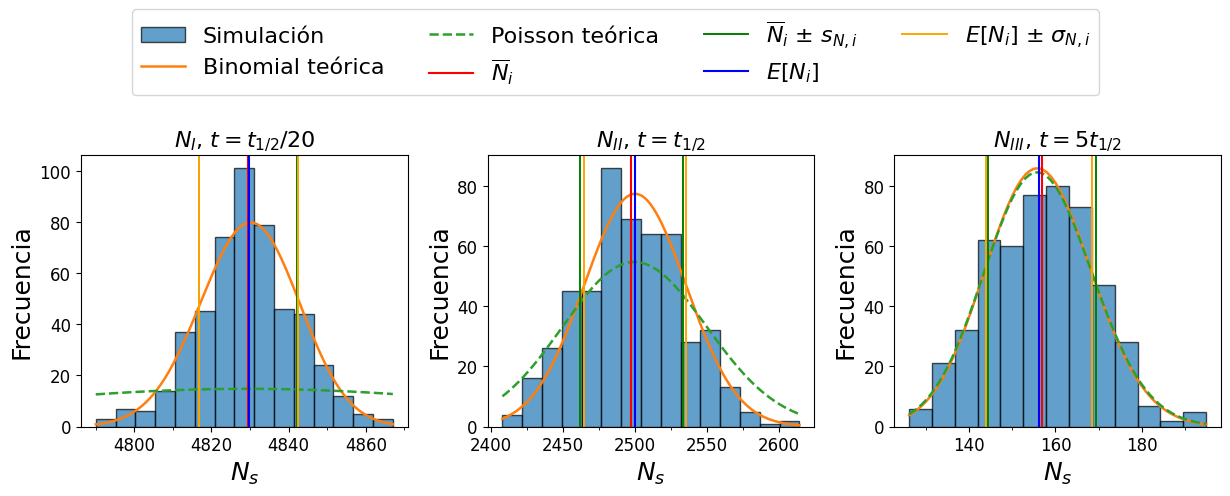

In [7]:
# ============================================================
# FIGURA PRINCIPAL: HISTOGRAMAS DE SUPERVIVIENTES
# ============================================================
# Esta figura es la recomendada para incluir en el cuerpo del trabajo.
# Los histogramas de desintegrados pueden mantenerse en el apéndice, porque
# son complementarios a los de supervivientes.


def representar_histogramas_supervivientes_principal(nombre_archivo):
    columnas = ["N_I", "N_II", "N_III"]
    fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.3))

    for ax, col in zip(axes, columnas):
        muestra = datos[col]
        variable, clave = col.split("_")
        pars = parametros_teoricos(variable, clave)
        simbolos = simbolos_variable(variable, generico=True)

        media_muestral = np.mean(muestra)
        sigma_muestral = np.std(muestra, ddof=1)

        info_hist = obtener_histograma_scott(col, muestra)
        edges = info_hist["edges"]
        anchurabin = info_hist["anchura"]

        k_min = int(muestra.min())
        k_max = int(muestra.max())
        k = np.arange(k_min, k_max + 1)

        frecuencia_binomial = M * binom.pmf(k, N0, pars["p_bin"])
        frecuencia_poisson = M * poisson.pmf(k, pars["media_poi"])

        ax.hist(
            muestra,
            bins=edges,
            color=COLOR_HISTOGRAMA,
            edgecolor="black",
            alpha=0.70,
            label="Simulación"
        )

        ax.plot(
            k,
            frecuencia_binomial * anchurabin,
            color=COLOR_BINOMIAL,
            linestyle="-",
            label="Binomial teórica"
        )

        ax.plot(
            k,
            frecuencia_poisson * anchurabin,
            color=COLOR_POISSON,
            linestyle="--",
            label="Poisson teórica"
        )

        # Media y desviación típica muestral
        ax.axvline(
            media_muestral,
            color=COLOR_MEDIA_MUESTRAL,
            linestyle="-",
            linewidth=1.5,
            label=simbolos["media_muestral"]
        )

        ax.axvline(
            media_muestral + sigma_muestral,
            color=COLOR_SIGMA_MUESTRAL,
            linestyle="-",
            linewidth=1.4,
            label=fr"{simbolos['media_muestral']} $\pm$ {simbolos['sigma_muestral']}"
        )

        ax.axvline(
            media_muestral - sigma_muestral,
            color=COLOR_SIGMA_MUESTRAL,
            linestyle="-",
            linewidth=1.4
        )

        # Media y desviación típica teórica binomial
        ax.axvline(
            pars["media_bin"],
            color=COLOR_MEDIA_TEORICA,
            linestyle="-",
            linewidth=1.5,
            label=simbolos["media_teorica"]
        )

        ax.axvline(
            pars["media_bin"] + pars["sigma_bin"],
            color=COLOR_SIGMA_TEORICA,
            linestyle="-",
            linewidth=1.4,
            label=fr"{simbolos['media_teorica']} $\pm$ {simbolos['sigma_teorica']}"
        )

        ax.axvline(
            pars["media_bin"] - pars["sigma_bin"],
            color=COLOR_SIGMA_TEORICA,
            linestyle="-",
            linewidth=1.4
        )

        ax.set_title(rf"$N_{{{clave}}}$, {etiqueta_instante(clave)}")
        ax.set_xlabel(simbolos["x"])
        ax.set_ylabel("Frecuencia")

        configurar_eje_histograma(ax, muestra)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=4,
    frameon=True,
    bbox_to_anchor=(0.5, 1.18),
    fontsize=16
)

    plt.tight_layout(rect=[0, 0, 1, 0.92])
    plt.savefig(nombre_archivo, dpi=300, bbox_inches="tight")
    plt.show()


representar_histogramas_supervivientes_principal(
    "histogramas_supervivientes_principal.png"
)


In [8]:
# ============================================================
# FIGURAS COMPLEMENTARIAS PARA EL APÉNDICE
# (3 filas x 1 columna)
# ============================================================


def representar_histogramas_vertical(lista_columnas, nombre_archivo, titulo_general):

    fig, axes = plt.subplots(3, 1, figsize=(7.2, 12.5))

    for ax, col in zip(axes, lista_columnas):

        muestra = datos[col]
        variable, clave = col.split("_")
        pars = parametros_teoricos(variable, clave)
        simbolos = simbolos_variable(variable, clave=clave)

        media_muestral = np.mean(muestra)
        sigma_muestral = np.std(muestra, ddof=1)

        info_hist = obtener_histograma_scott(col, muestra)
        edges = info_hist["edges"]
        anchurabin = info_hist["anchura"]

        k_min = int(muestra.min())
        k_max = int(muestra.max())
        k = np.arange(k_min, k_max + 1)

        frecuencia_binomial = M * binom.pmf(k, N0, pars["p_bin"])
        frecuencia_poisson = M * poisson.pmf(k, pars["media_poi"])

        ax.hist(
            muestra,
            bins=edges,
            color=COLOR_HISTOGRAMA,
            edgecolor="black",
            alpha=0.70,
            label="Simulación"
        )

        ax.plot(
            k,
            frecuencia_binomial * anchurabin,
            color=COLOR_BINOMIAL,
            linestyle="-",
            label="Binomial teórica"
        )

        ax.plot(
            k,
            frecuencia_poisson * anchurabin,
            color=COLOR_POISSON,
            linestyle="--",
            label="Poisson teórica"
        )

        # Media y desviación típica muestral
        ax.axvline(
            media_muestral,
            color=COLOR_MEDIA_MUESTRAL,
            linestyle="-",
            linewidth=1.5,
            label=fr"{simbolos['media_muestral']} = ${numero_latex(media_muestral, 2)}$"
        )

        ax.axvline(
            media_muestral + sigma_muestral,
            color=COLOR_SIGMA_MUESTRAL,
            linestyle="-",
            linewidth=1.4,
            label=fr"{simbolos['media_muestral']} $\pm$ {simbolos['sigma_muestral']} = ${numero_latex(sigma_muestral, 2)}$"
        )

        ax.axvline(
            media_muestral - sigma_muestral,
            color=COLOR_SIGMA_MUESTRAL,
            linestyle="-",
            linewidth=1.4
        )

        # Media y desviación típica teórica binomial
        ax.axvline(
            pars["media_bin"],
            color=COLOR_MEDIA_TEORICA,
            linestyle="-",
            linewidth=1.5,
            label=fr"{simbolos['media_teorica']} = ${numero_latex(pars['media_bin'], 2)}$"
        )

        ax.axvline(
            pars["media_bin"] + pars["sigma_bin"],
            color=COLOR_SIGMA_TEORICA,
            linestyle="-",
            linewidth=1.4,
            label=fr"{simbolos['media_teorica']} $\pm$ {simbolos['sigma_teorica']} = ${numero_latex(pars['sigma_bin'], 2)}$"
        )

        ax.axvline(
            pars["media_bin"] - pars["sigma_bin"],
            color=COLOR_SIGMA_TEORICA,
            linestyle="-",
            linewidth=1.4
        )

        ax.set_title(rf"${variable}_{{{clave}}}$, {etiqueta_instante(clave)}")
        ax.set_xlabel(simbolos["x"])
        ax.set_ylabel("Frecuencia")

        configurar_eje_histograma(ax, muestra)

        ax.legend(
            fontsize=8,
            loc="upper right",
            frameon=True,
            labelspacing=0.4,
            handlelength=1.7,
            borderpad=0.5
        )

    
    plt.tight_layout(rect=[0, 0, 1, 0.98])
    plt.savefig(nombre_archivo, dpi=300, bbox_inches="tight")
    plt.show()


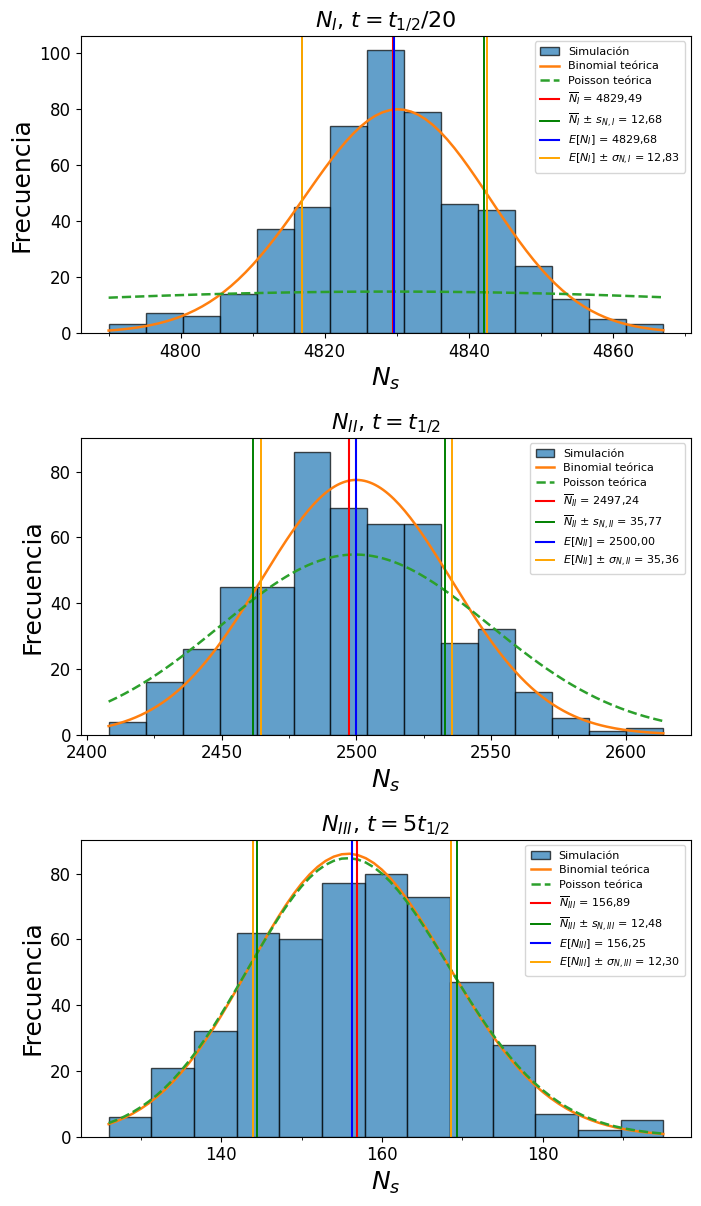

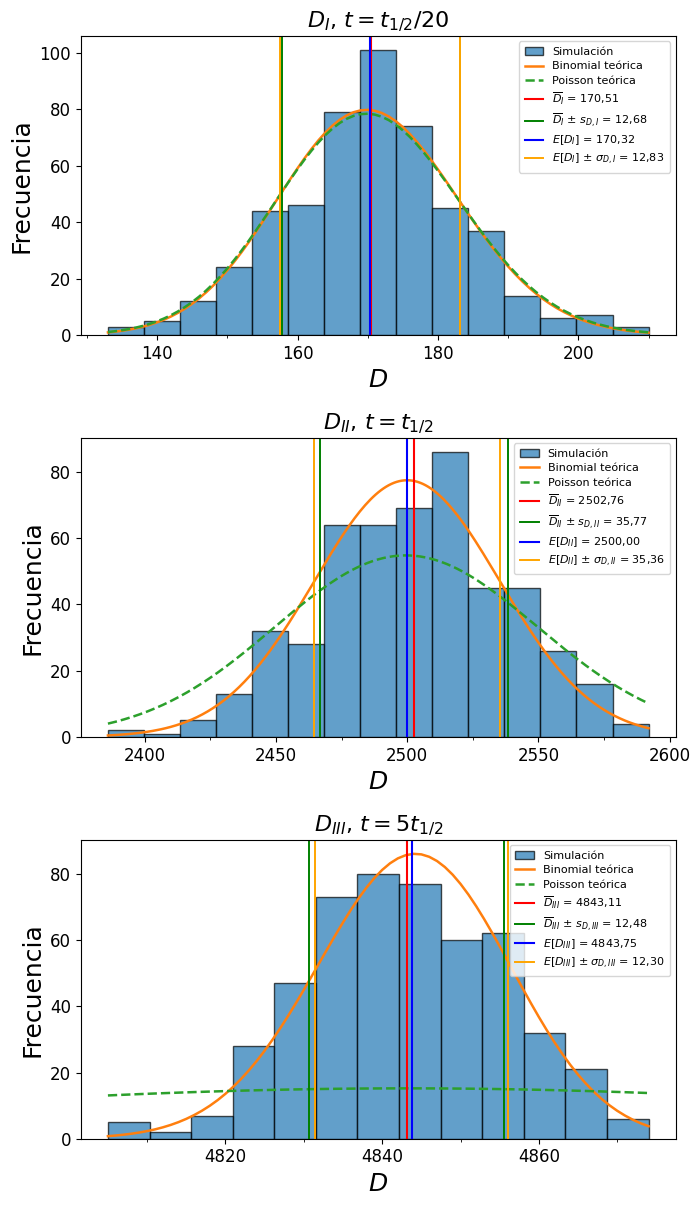

In [9]:
# ============================================================
# FIGURA COMPLEMENTARIA 1: SUPERVIVIENTES
# ============================================================

representar_histogramas_vertical(
    lista_columnas=["N_I", "N_II", "N_III"],
    nombre_archivo="histogramas_supervivientes_vertical.png",
    titulo_general="Distribución del número de núcleos supervivientes"
)

# ============================================================
# FIGURA COMPLEMENTARIA 2: DESINTEGRADOS
# ============================================================

representar_histogramas_vertical(
    lista_columnas=["D_I", "D_II", "D_III"],
    nombre_archivo="histogramas_desintegrados_vertical.png",
    titulo_general="Distribución del número de núcleos desintegrados"
)
